<a href="https://colab.research.google.com/github/zaaz-png/results/blob/main/fds_expt6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
from google.colab import files
uploaded= files.upload()
data=pd.read_csv('cleaned_dataset2.csv')

Saving cleaned_dataset2.csv to cleaned_dataset2.csv


DATA NORMLAIZATION
1. MIN-MAX NOMALIZATION
considering column age for min max

In [5]:
print(data['Age'].min())
print(data['Age'].max())

2
90


In [4]:
min=data['Age'].min()
max=data['Age'].max()
data['Age']=(data['Age']-min)/(max-min)

2. z-score : wrt albumin in urine column

In [5]:
data['Albumin in urine']= (data['Albumin in urine']- data['Albumin in urine'].mean()) / data['Albumin in urine'].std()

3. decimal scaling: wrt wbc count column

In [6]:
print(data['WBC count'].max())

11999


In [7]:
data['WBC count']= data['WBC count']/ 10**5   #since the largest value of wbc count column contains 5 digits.

NORMALIZED COLUMNS

In [12]:
data[['Age', 'Albumin in urine', 'WBC count']].head(20)

,Age,Albumin in urine,WBC count
0,0.522727,-0.720387,0.11319
1,0.056818,-0.723569,0.11018
2,0.681818,-0.720387,0.05479
3,0.522727,-0.714022,0.07817
4,0.556818,-0.714022,0.03055
5,0.659091,-0.723569,0.06325
6,0.750000,-0.720387,0.03799
7,0.250000,-0.720387,0.05310
8,0.568182,-0.723569,0.11243
9,0.579545,-0.714022,0.10054


DATA DISCRETIZATION

In [16]:
print(data['Blood Pressure'].min())
print(data['Blood Pressure'].max())

50
180


using elbow method to find k

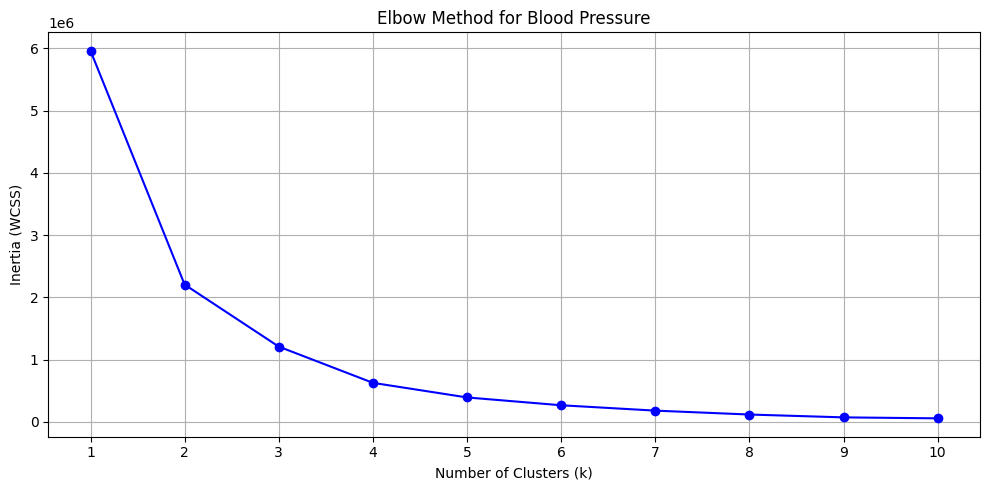

In [26]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# Prepare the data
bp_data = data[['Blood Pressure']].dropna()

# Compute WCSS (inertia) for a range of k values
range_k = range(1, 11)
inertia_bp = []

for k in range_k:
    kmeans_bp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_bp.fit(bp_data)
    inertia_bp.append(kmeans_bp.inertia_)

# Plot the Elbow Method graphs
fig, axes = plt.subplots(figsize=(10,5))

# Blood Pressure Elbow Plot
axes.plot(range_k, inertia_bp, marker='o', color='b')
axes.set_title('Elbow Method for Blood Pressure')
axes.set_xlabel('Number of Clusters (k)')
axes.set_ylabel('Inertia (WCSS)')
axes.set_xticks(range_k)
axes.grid(True)

plt.tight_layout()
plt.show()

from graph, k=3

In [24]:
from sklearn.cluster import KMeans
import numpy as np

# Fit KMeans on Blood Pressure with k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['BP_Cluster'] = kmeans.fit_predict(data[['Blood Pressure']])

# Display the cluster centers (representing the average blood pressure of each cluster)
centers = np.sort(kmeans.cluster_centers_.flatten())
print(f"Cluster Centers (Average Blood Pressure for each cluster): {centers}\n")

# View the results
display(data[['Blood Pressure', 'BP_Cluster']])

Cluster Centers (Average Blood Pressure for each cluster): [ 71.29488426  97.48550175 118.73999398]



,Blood Pressure,BP_Cluster
0,178,0
1,138,0
2,165,0
3,141,0
4,175,0
...,...,...
15046,137,0
15047,137,0
15048,177,0
15049,177,0


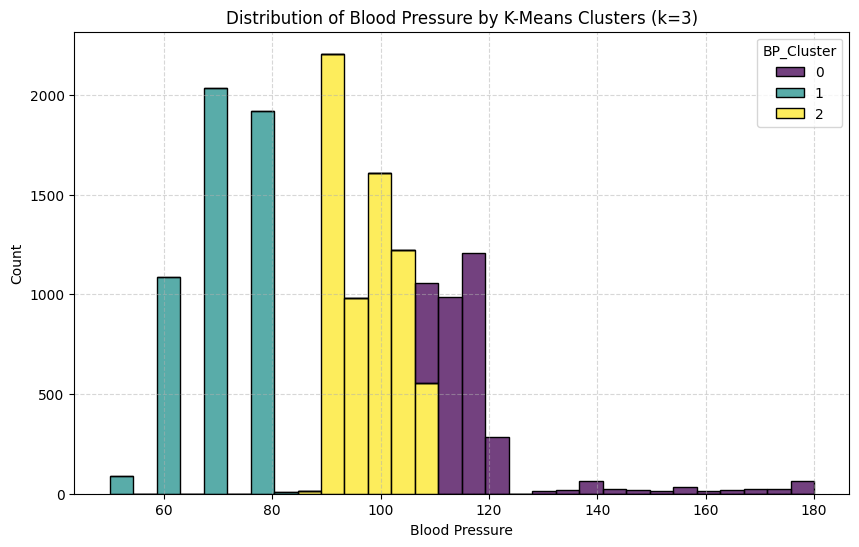

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a histogram of Blood Pressure colored by their cluster assignment
plt.figure(figsize=(10, 6))
sns.histplot(data=data, x='Blood Pressure', hue='BP_Cluster', palette='viridis', multiple='stack', bins=30)

# Add titles and labels
plt.title('Distribution of Blood Pressure by K-Means Clusters (k=3)')
plt.xlabel('Blood Pressure')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

The algorithm found the following average values for each group:

1. Cluster 0: Average BP of 118.7 (representing high blood pressure ranges)
2. Cluster 1: Average BP of 97.5 (representing intermediate/pre-high blood pressure ranges)
3. Cluster 2: Average BP of 71.3 (representing lower/normal blood pressure ranges)

These 3 clusters serve as the new discrete groups for the Blood Pressure attribute.

